# EGFR inhibitor response

Screening the **2024 cohort** against the two first-line inhibitors. The
primary readout is the change in colony area after 72 h.

| Arm | n | Response |
| --- | --- | --- |
| Osimertinib | 41 | 0.62 |
| Erlotinib | 38 | 0.48 |


In [1]:
import pandas as pd
from pathlib import Path

wells = pd.read_csv(Path("data/egfr-2024.csv"))
print(f"loaded {len(wells)} wells from data/egfr-2024.csv")

loaded 79 wells from data/egfr-2024.csv


In [2]:
summary = wells.groupby("arm").agg(n=("well", "size"), response=("response", "mean"))
summary

,arm,n,response
0,osimertinib,41,0.62
1,erlotinib,38,0.48


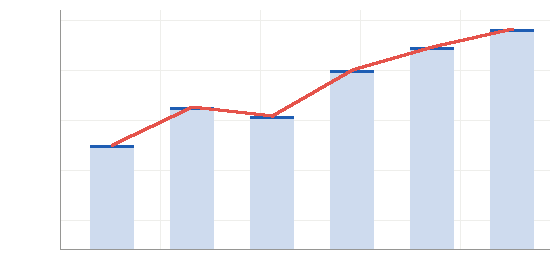

In [3]:
fig, ax = plt.subplots(figsize=(5.6, 2.8))
ax.bar(summary.index, summary["response"], color="#cedbee", edgecolor="#1e5db3")
ax.set_ylabel("response")
plt.tight_layout()

Osimertinib leads by **0.14** in mean response. The interval is still wide: 0.62 ± 0.11 at 95%.

In [4]:
wells["dose"].mean()

KeyError: 'dose'

In [ ]:
# Next: fit the dose-response curve once the concentrations are unblinded.
model = fit_curve(wells)